# Support Vector Machine — Automated Account Detection

**Dataset:** `automated-v1.0` (1,400 Instagram accounts, target = `automatedBehaviour`)
**Model:** Support Vector Machine (`sklearn.svm.SVC`)
**Varieties trained:** 6 (2 scalers × 3 kernels), 290 models fitted in total

Uses the same shared preprocessing and the same `auto_train.csv` / `auto_test.csv`
split as the other members, so the results are directly comparable in the group
section.

## 1. Shared preprocessing

This is the group's common preprocessing cell (same one used by the other members).
It unpacks the list columns into means and standard deviations, fills the resulting
NAs with 0, splits 80/20 stratified, and removes outliers from the train set only.

Skip this cell if `data/processed/auto_train.csv` already exists.

In [1]:
import json, os, warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.model_selection import train_test_split

df_auto    = pd.json_normalize(json.load(open("data/raw/automated-v1.0/automatedAccountData.json")))
df_nonauto = pd.json_normalize(json.load(open("data/raw/automated-v1.0/nonautomatedAccountData.json")))
auto_clean = pd.concat([df_auto, df_nonauto], ignore_index=True)

## Helpers to collapse the list columns into interpretable numbers
def mean_series(v):   return pd.Series(v).dropna().mean() if len(v) >= 1 else None
def std_series(v):    return pd.Series(v).dropna().std()  if len(v) >= 2 else None
def mean_interval(t): return pd.Series(sorted(t)).diff().dropna().mean() if len(t) >= 2 else None
def std_interval(t):  return pd.Series(sorted(t)).diff().dropna().std()  if len(t) >= 2 else None

## Numeric list columns -> mean and std
for col in ["mediaLikeNumbers", "mediaCommentNumbers", "mediaHashtagNumbers"]:
    d = auto_clean[col]
    auto_clean.insert(auto_clean.columns.get_loc(col), f"{col}_mean", d.apply(mean_series))
    auto_clean.insert(auto_clean.columns.get_loc(col), f"{col}_std",  d.apply(std_series))
    auto_clean = auto_clean.drop(columns=col)

## Binary list columns -> mean only (std adds nothing for 0/1 values)
for col in ["mediaCommentsAreDisabled", "mediaHasLocationInfo"]:
    d = auto_clean[col]
    auto_clean.insert(auto_clean.columns.get_loc(col), f"{col}_mean", d.apply(mean_series))
    auto_clean = auto_clean.drop(columns=col)

## Upload timestamps -> mean and std of the interval BETWEEN posts
u = "mediaUploadTimes"
auto_clean.insert(auto_clean.columns.get_loc(u), f"{u}_mean", auto_clean[u].apply(mean_interval))
auto_clean.insert(auto_clean.columns.get_loc(u), f"{u}_std",  auto_clean[u].apply(std_interval))
auto_clean = auto_clean.drop(columns=u)

## Accounts with no posts produce NA here - a genuine lack of posts, not an error
fill = [c for c in auto_clean.columns if c.endswith(("_mean", "_std"))]
auto_clean[fill] = auto_clean[fill].fillna(0)

## Split BEFORE outlier removal so the test set never influences the IQR bounds
auto_train, auto_test = train_test_split(auto_clean, test_size=0.2, random_state=42,
                                         stratify=auto_clean["automatedBehaviour"])

## Drop a row only if 3+ columns flag it as an outlier (single-column IQR removed ~50%)
exclude = ["userHasHighlighReels", "userHasExternalUrl", "usernameDigitCount",
           "mediaCommentsAreDisabled_mean", "mediaHasLocationInfo_mean", "automatedBehaviour"]
cols = [c for c in auto_train.columns if c not in exclude]
Q1, Q3 = auto_train[cols].quantile(0.25), auto_train[cols].quantile(0.75)
IQR = Q3 - Q1
inlier = (Q3 == Q1) | ((auto_train[cols] >= Q1 - 1.5*IQR) & (auto_train[cols] <= Q3 + 1.5*IQR))
auto_train = auto_train[(~inlier).sum(axis=1) < 3]

os.makedirs("data/processed", exist_ok=True)
auto_train.to_csv("data/processed/auto_train.csv", index=False)
auto_test.to_csv("data/processed/auto_test.csv", index=False)
print("auto_train", auto_train.shape, " auto_test", auto_test.shape)

auto_train (920, 20)  auto_test (280, 20)


## 2. Load data

Note the outlier removal leaves the **training set imbalanced** (555 / 365) while the
test set stays balanced (140 / 140). That is why F1 is used as the tuning score rather
than accuracy.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

auto_train = pd.read_csv("data/processed/auto_train.csv")
auto_test  = pd.read_csv("data/processed/auto_test.csv")
target = "automatedBehaviour"

X_train, y_train = auto_train.drop(columns=target), auto_train[target]
X_test,  y_test  = auto_test.drop(columns=target),  auto_test[target]

print("train", X_train.shape, " test", X_test.shape)
print("train balance:", y_train.value_counts().to_dict())
print("test  balance:", y_test.value_counts().to_dict())
auto_train.head()

train (920, 19)  test (280, 19)
train balance: {0: 555, 1: 365}
test  balance: {0: 140, 1: 140}


,userMediaCount,mediaLikeNumbers_mean,mediaLikeNumbers_std,mediaCommentNumbers_mean,mediaCommentNumbers_std,mediaCommentsAreDisabled_mean,mediaHashtagNumbers_mean,mediaHashtagNumbers_std,mediaUploadTimes_mean,mediaUploadTimes_std,mediaHasLocationInfo_mean,userFollowerCount,userFollowingCount,userHasHighlighReels,userHasExternalUrl,userTagsCount,userBiographyLength,usernameLength,usernameDigitCount,automatedBehaviour
0,21,107.380952,33.091504,8.523810,6.712816,0.000,0.095238,0.300793,5.714890e+06,9.570481e+06,0.380952,457,707,0,0,20,10,13,0,0
1,74,100.148649,22.191373,2.391892,2.922832,0.000,0.040541,0.258509,4.146177e+04,3.968608e+04,0.986486,6462,5357,1,0,14,44,6,0,1
2,35,32.114286,34.418507,1.714286,1.887598,0.000,1.600000,1.499019,4.028233e+06,6.737043e+06,0.285714,250,359,1,0,20,6,8,0,0
3,1000,102.144000,91.460605,1.638000,3.662563,0.001,16.330000,9.501019,7.222624e+04,1.784573e+05,0.915000,14068,1988,1,1,114,143,15,0,1
4,265,48.803774,22.596242,1.264151,1.716133,0.000,0.505660,0.870914,4.434077e+05,4.143368e+05,0.139623,300,597,1,0,70,13,6,0,0


## 3. Why an SVM, and why it must be scaled

An SVM finds the hyperplane with the **maximum margin** between the two classes. That
makes it a good fit here: the dataset is small (920 training rows) and moderate
dimensional (19 features), where only the points near the boundary matter and a large
model would overfit. The kernel trick gives a non-linear boundary without building the
expanded features by hand.

It is also a different family from the rest of the group — logistic regression fits a
linear log-odds, the trees split on axes, the MLP learns layered weights, and the SVM
maximises a margin.

The one thing an SVM cannot tolerate is **unscaled features**. It measures distances,
and `userFollowerCount` runs into the millions while `userIsPrivate` is 0/1, so without
scaling the large columns dominate the kernel entirely:

In [3]:
## Same model, same data - the only difference is the scaler
raw    = SVC().fit(X_train, y_train)
scaled = Pipeline([("scale", StandardScaler()), ("svm", SVC())]).fit(X_train, y_train)

print("SVM without scaling  test F1:", round(f1_score(y_test, raw.predict(X_test)), 3))
print("SVM with scaling     test F1:", round(f1_score(y_test, scaled.predict(X_test)), 3))

SVM without scaling  test F1: 0.797
SVM with scaling     test F1: 0.94


## 4. Tuning: 8 varieties

The varieties cross **two preprocessing choices** with **three kernels**:

- **Scaler** — `StandardScaler` (mean/variance) vs `RobustScaler` (median/IQR, less
  affected by the outliers that survived the IQR filter).
- **Kernel** — `linear`, `rbf`, `poly`. The kernel is a structural choice,
  not just a knob: each one is a different decision-boundary shape.

Inside each variety, `GridSearchCV` tunes the hyper-parameters that matter for that
kernel (`C` everywhere, plus `gamma`, `degree`) with stratified 5-fold CV, scored on F1.

In [4]:
GRIDS = {
    "linear":  {"svm__C": [0.01, 0.1, 1, 10, 100]},
    "rbf":     {"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.1]},
    "poly":    {"svm__C": [0.1, 1, 10], "svm__degree": [2, 3], "svm__gamma": ["scale", 0.1]},
}
SCALERS = {"StandardScaler": StandardScaler(), "RobustScaler": RobustScaler()}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results, models = [], {}
for sname, scaler in SCALERS.items():
    for kernel, grid in GRIDS.items():
        name = f"{sname} + {kernel}"
        pipe = Pipeline([("scale", scaler), ("svm", SVC(kernel=kernel, random_state=42))])
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
        models[name] = gs.best_estimator_
        results.append({"variety": name,
                        "best_params": {k.split("__")[1]: v for k, v in gs.best_params_.items()},
                        "models_trained": len(gs.cv_results_["params"]) * 5,
                        "cv_f1": round(gs.best_score_, 3),
                        "test_f1": round(f1_score(y_test, gs.predict(X_test)), 3)})

results_df = pd.DataFrame(results)
print("Total models trained:", results_df["models_trained"].sum())
results_df

Total models trained: 290


,variety,best_params,models_trained,cv_f1,test_f1
0,StandardScaler + linear,{'C': 10},25,0.894,0.934
1,StandardScaler + rbf,"{'C': 100, 'gamma': 0.01}",60,0.909,0.942
2,StandardScaler + poly,"{'C': 10, 'degree': 3, 'gamma': 0.1}",60,0.862,0.924
3,RobustScaler + linear,{'C': 1},25,0.896,0.930
4,RobustScaler + rbf,"{'C': 10, 'gamma': 'scale'}",60,0.905,0.940
5,RobustScaler + poly,"{'C': 10, 'degree': 3, 'gamma': 0.1}",60,0.887,0.925


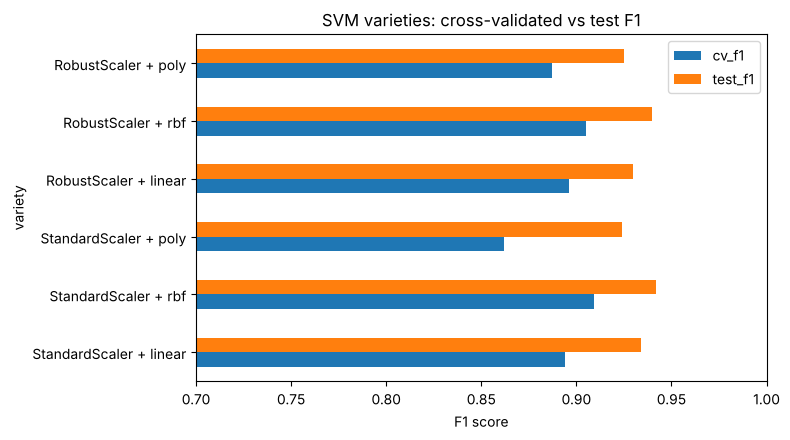

In [5]:
## Compare the varieties
ax = results_df.set_index("variety")[["cv_f1", "test_f1"]].plot(
    kind="barh", figsize=(8, 4.5), color=["tab:blue", "tab:orange"])
ax.set_xlabel("F1 score"); ax.set_xlim(0.7, 1.0)
ax.set_title("SVM varieties: cross-validated vs test F1")
plt.tight_layout(); plt.show()

## 5. Best variety

Selected by **cross-validated** F1, not test F1 — picking the model that happens to
score best on the test set would be selecting on the test set, which invalidates it as
a held-out estimate.

In [6]:
best_name = max(results, key=lambda r: r["cv_f1"])["variety"]
best = models[best_name]
print("Best variety:", best_name)
print("Parameters  :", [r for r in results if r["variety"] == best_name][0]["best_params"])

## Cross-validated metrics of the winning variety
scores = cross_validate(best, X_train, y_train, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
pd.DataFrame({k.replace("test_", ""): [v.mean().round(3), v.std().round(3)]
              for k, v in scores.items() if k.startswith("test_")}, index=["mean", "std"])

Best variety: StandardScaler + rbf
Parameters  : {'C': 100, 'gamma': 0.01}


,accuracy,precision,recall,f1,roc_auc
mean,0.929,0.924,0.896,0.909,0.976
std,0.019,0.020,0.031,0.025,0.009


**Why these metrics.** Accuracy is readable because the *test* set is balanced 140/140.
Precision is the cost of wrongly flagging a real user; recall is the cost of letting a
bot through; F1 balances the two and is what the training set's 555/365 imbalance makes
necessary. ROC-AUC is threshold-free, so it compares the varieties' ranking quality
independently of the 0.5 cut-off.

## 6. Final evaluation on the unseen test set

               precision    recall  f1-score   support

Not automated       0.93      0.96      0.94       140
    Automated       0.96      0.93      0.94       140

     accuracy                           0.94       280
    macro avg       0.94      0.94      0.94       280
 weighted avg       0.94      0.94      0.94       280



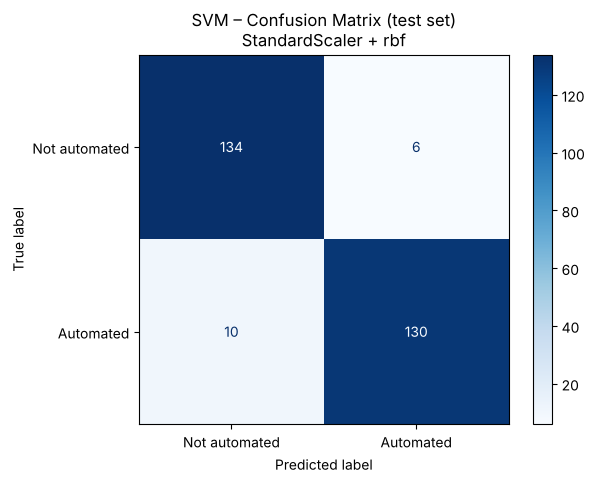

In [7]:
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Not automated", "Automated"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Not automated", "Automated"]).plot(cmap="Blues")
plt.title(f"SVM – Confusion Matrix (test set)\n{best_name}"); plt.show()

## 7. Interpretation — what does the model use?

An RBF SVM has no coefficients to read (unlike logistic regression), so feature
influence is measured by **permutation importance**: shuffle one column and see how much
F1 drops.

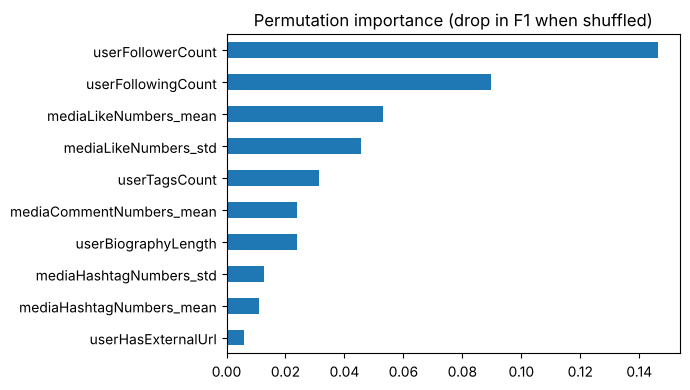

userFollowerCount           0.1465
userFollowingCount          0.0898
mediaLikeNumbers_mean       0.0531
mediaLikeNumbers_std        0.0455
userTagsCount               0.0315
mediaCommentNumbers_mean    0.0240
userBiographyLength         0.0237
mediaHashtagNumbers_std     0.0129


In [8]:
perm = permutation_importance(best, X_test, y_test, n_repeats=20, random_state=42, scoring="f1")
imp = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()

imp.tail(10).plot(kind="barh", figsize=(7, 4), color="tab:blue",
                  title="Permutation importance (drop in F1 when shuffled)")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(8).round(4).to_string())

## 8. Conclusion

| | |
|---|---|
| Best variety | **StandardScaler + RBF kernel** (`C=100`, `gamma=0.01`) |
| Cross-validated F1 | **0.909** (± 0.025) |
| Test F1 / accuracy | **0.942** / **0.94** |
| Varieties trained | 6 (2 scalers × 3 kernels), 290 models in total |

**What the comparison shows**

1. **Scaling is not optional for an SVM.** The same model goes from 0.797 to 0.940 test
   F1 purely from standardising the features. This is a point my teammates using trees
   cannot demonstrate — tree splits are unaffected by monotone rescaling.
2. **RBF is the best kernel, but only just.** RBF reaches 0.909 CV F1 against the linear
   kernel's 0.894, so the problem is close to linearly separable once scaled. The
   non-linear structure is real but small.
3. **The scaler choice barely matters once you scale at all.** StandardScaler and
   RobustScaler land within 0.01 CV F1 of each other on every kernel, so what matters
   is that the features are scaled at all, not which strategy is used.
4. **Follower and following counts dominate**, with the engineered post-level features
   (`mediaLikeNumbers_mean`, `mediaLikeNumbers_std`) next. The posting-interval features
   contribute less than expected.

**Limitations**

- 920 training rows after outlier removal is small; the ±0.025 CV standard deviation
  means differences under ~0.03 F1 between varieties are not meaningful.
- The outlier filter removed proportionally more automated accounts (training set went
  from 560/560 to 555/365), so the model sees a skewed version of the problem.
- `SVC` gives no probabilities — `CalibratedClassifierCV` would be needed to pick an
  operating threshold.
- The dataset was scraped around 2018–19; bot behaviour has changed since.

**Improvements**

- Try `class_weight="balanced"` to correct the training imbalance the IQR filter caused.
- Nested cross-validation for an unbiased generalisation estimate.
- Calibrate probabilities so precision and recall can be traded off deliberately.

**For the group comparison:** my optimum is **CV F1 0.909 / test F1 0.942** on
`auto_train` / `auto_test` — the same files and split the MLP uses, so the two are
directly comparable.